In [1]:
import pandas as pd

cluster2 = pd.read_csv('./results/PPI/cluster2_annotations.tsv', sep='\t')
cluster2_genes = cluster2['#node'].tolist()
print(f"Cluster 2 genes: {len(cluster2_genes)}")

consensus_df = pd.read_csv('./results/DEG/consensus_DEGs.csv')

cluster2_directions = consensus_df[consensus_df['Gene'].isin(cluster2_genes)]
up = (cluster2_directions['direction'] == 'Up').sum()
down = (cluster2_directions['direction'] == 'Down').sum()

print(f"Upregulated: {up} ({up/len(cluster2_directions)*100:.1f}%)")
print(f"Downregulated: {down} ({down/len(cluster2_directions)*100:.1f}%)")

Cluster 2 genes: 93
Upregulated: 3 (3.2%)
Downregulated: 90 (96.8%)


In [ ]:
# Load raw CytoHubba CSVs
mcc_raw_c2 = pd.read_csv('./results/PPI/cluster2_MCC_top10.csv', skiprows=1)
betweenness_raw_c2 = pd.read_csv('./results/PPI/cluster2_betweenness_top10.csv', skiprows=1)

# Build ENSP → gene symbol lookup directly from annotations
ensp_to_gene = dict(zip(
    cluster2['identifier'].str.replace('9606.', '', regex=False),
    cluster2['#node']
))

# Map ENSP IDs to gene symbols
mcc_ids_c2 = [id.replace('9606.', '') for id in mcc_raw_c2['Name'].tolist()]
betweenness_ids_c2 = [id.replace('9606.', '') for id in betweenness_raw_c2['Name'].tolist()]

mcc_genes_c2 = [ensp_to_gene.get(id, id) for id in mcc_ids_c2]
betweenness_genes_c2 = [ensp_to_gene.get(id, id) for id in betweenness_ids_c2]

mcc_only_c2 = set(mcc_genes_c2) - set(betweenness_genes_c2)
betweenness_only_c2 = set(betweenness_genes_c2) - set(mcc_genes_c2)
both_c2 = set(mcc_genes_c2) & set(betweenness_genes_c2)

print("MCC top 10:", mcc_genes_c2)
print("Betweenness top 10:", betweenness_genes_c2)
print(f"MCC only: {mcc_only_c2}")
print(f"Betweenness only: {betweenness_only_c2}")
print(f"Both: {both_c2}")
print(f"Overlap count: {len(both_c2)}")

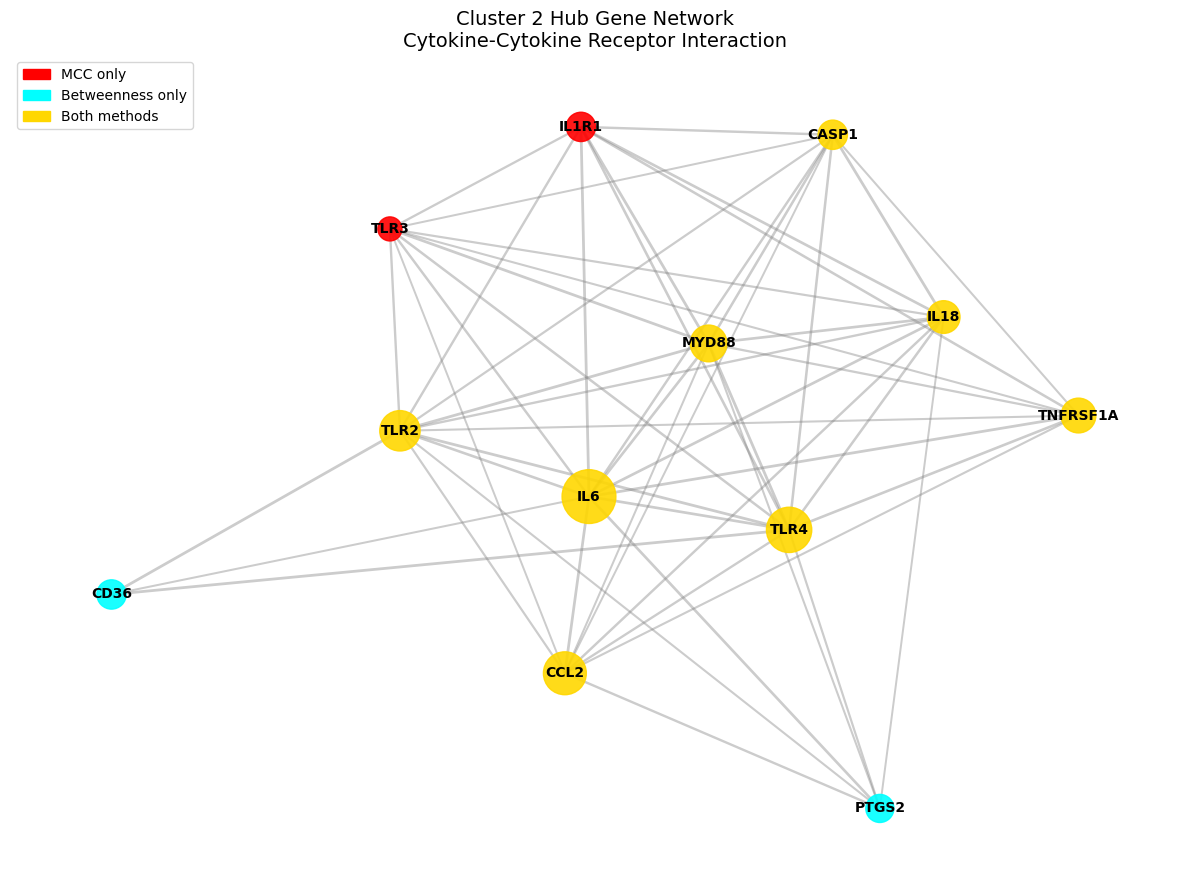

In [9]:
edges_c2 = pd.read_csv('./results/PPI/cluster2_edges.tsv', sep='\t')
degrees_c2 = pd.read_csv('./results/PPI/cluster2_degrees.tsv', sep='\t')

all_hubs_c2 = set(mcc_genes_c2) | set(betweenness_genes_c2)

hub_edges_c2 = edges_c2[
    (edges_c2['#node1'].isin(all_hubs_c2)) & 
    (edges_c2['node2'].isin(all_hubs_c2))
]

import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

G2 = nx.Graph()
for _, row in hub_edges_c2.iterrows():
    G2.add_edge(row['#node1'], row['node2'], weight=row['combined_score'])

# Color by method
color_map_c2 = []
for node in G2.nodes():
    if node in both_c2:
        color_map_c2.append('gold')
    elif node in mcc_only_c2:
        color_map_c2.append('red')
    else:
        color_map_c2.append('cyan')

# Normalize node sizes
degrees = [degrees_c2[degrees_c2['#node'] == node]['node_degree'].values[0] 
           for node in G2.nodes()]
min_deg, max_deg = min(degrees), max(degrees)
node_sizes = [300 + (d - min_deg) / (max_deg - min_deg) * 1200 for d in degrees]

edge_weights = [G2[u][v]['weight'] * 2 for u, v in G2.edges()]

plt.figure(figsize=(12, 9))
pos = nx.spring_layout(G2, seed=42, k=2)

nx.draw_networkx_nodes(G2, pos, node_color=color_map_c2, node_size=node_sizes, alpha=0.9)
nx.draw_networkx_edges(G2, pos, width=edge_weights, alpha=0.4, edge_color='grey')
nx.draw_networkx_labels(G2, pos, font_size=10, font_weight='bold')

legend = [mpatches.Patch(color='red', label='MCC only'),
          mpatches.Patch(color='cyan', label='Betweenness only'),
          mpatches.Patch(color='gold', label='Both methods')]
plt.legend(handles=legend, loc='upper left')

plt.title('Cluster 2 Hub Gene Network\nCytokine-Cytokine Receptor Interaction', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.savefig('./figures/cluster2_hub_network.png', dpi=150)
plt.show()